In [1]:
import os
import numpy as np
import pandas as pd

from dotenv import load_dotenv
from sqlalchemy import create_engine, text

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt

load_dotenv()
engine = create_engine(os.getenv("DATABASE_URL"))

In [2]:
from sqlalchemy import text
import pandas as pd

SNAPSHOT_DATES = pd.read_sql(
    "SELECT DISTINCT feature_date FROM hpce.decision_engine_output_daily ORDER BY feature_date",
    engine
)["feature_date"].astype(str).tolist()

LATEST_SNAP = SNAPSHOT_DATES[-1]
print("Latest snapshot:", LATEST_SNAP, "| total snapshot dates:", len(SNAPSHOT_DATES))

q = text("""
SELECT
  customer_id,
  feature_date,
  daily_orders,
  daily_spend,
  f_30,
  m_30,
  f_trend_30,
  m_trend_30,
  recency_days
FROM hpce.customer_features_daily
WHERE feature_date IN :snaps
""")

df = pd.read_sql(q, engine, params={"snaps": tuple(SNAPSHOT_DATES)})
df["feature_date"] = pd.to_datetime(df["feature_date"])

print("Rows:", len(df))
print("Unique dates:", df["feature_date"].dt.date.nunique())
print(df["feature_date"].dt.date.value_counts().sort_index())
df.head()

Latest snapshot: 2018-08-04 | total snapshot dates: 34
Rows: 14725
Unique dates: 34
feature_date
2018-07-02    476
2018-07-03    495
2018-07-04    530
2018-07-05    467
2018-07-06    391
2018-07-07    359
2018-07-08    385
2018-07-09    408
2018-07-10    391
2018-07-11    384
2018-07-12    375
2018-07-13    420
2018-07-14    394
2018-07-15    402
2018-07-16    486
2018-07-17    454
2018-07-18    527
2018-07-19    473
2018-07-20    463
2018-07-21    394
2018-07-22    422
2018-07-23    506
2018-07-24    463
2018-07-25    457
2018-07-26    429
2018-07-27    371
2018-07-28    354
2018-07-29    358
2018-07-30    451
2018-07-31    485
2018-08-01    467
2018-08-02    456
2018-08-03    457
2018-08-04    375
Name: count, dtype: int64


,customer_id,feature_date,daily_orders,daily_spend,f_30,m_30,f_trend_30,m_trend_30,recency_days
0,000fbf0473c10fc1ab6f8d2d286ce20c,2018-07-26,1,362.36,1.0,362.36,1.0,362.36,0
1,00172711b30d52eea8b313a7f2cced02,2018-07-28,1,122.07,1.0,122.07,1.0,122.07,0
2,00196c4c9a3af7dd2ad10eade69c926f,2018-07-28,1,37.58,1.0,37.58,1.0,37.58,0
3,003fb95e849e71e732629d94bb92762f,2018-07-30,1,77.59,1.0,77.59,1.0,77.59,0
4,005f6fa02633470267dcd1e3ecd0fa79,2018-07-27,1,272.04,1.0,272.04,1.0,272.04,0


In [3]:
q_ev = text("""
SELECT
  customer_id,
  feature_date,
  views_30,
  carts_30,
  events_30,
  event_recency_days,
  cart_to_view_rate_30
FROM hpce.decision_engine_output_daily
WHERE feature_date IN :snaps
""")

try:
    ev = pd.read_sql(q_ev, engine, params={"snaps": tuple(SNAPSHOT_DATES)})
    ev["feature_date"] = pd.to_datetime(ev["feature_date"])

    df = df.merge(ev, on=["customer_id","feature_date"], how="left")

    for c in ["views_30","carts_30","events_30","event_recency_days","cart_to_view_rate_30"]:
        df[c] = df[c].fillna(0)

    print("✅ Joined events. Shape:", df.shape)
except Exception as e:
    print("⚠️ Events table join skipped:", str(e)[:200])


✅ Joined events. Shape: (14725, 14)


In [4]:
import numpy as np

CLUSTER_FEATURES = [
    "recency_days","f_30","m_30","f_trend_30","m_trend_30","daily_orders","daily_spend"
]

for c in ["events_30","event_recency_days","views_30","carts_30","cart_to_view_rate_30"]:
    if c in df.columns:
        CLUSTER_FEATURES.append(c)

X_all = df[CLUSTER_FEATURES].replace([np.inf,-np.inf], np.nan).fillna(0)
print("Features used:", CLUSTER_FEATURES)
X_all.describe().T

Features used: ['recency_days', 'f_30', 'm_30', 'f_trend_30', 'm_trend_30', 'daily_orders', 'daily_spend', 'events_30', 'event_recency_days', 'views_30', 'carts_30', 'cart_to_view_rate_30']


,count,mean,std,min,25%,50%,75%,max
recency_days,14725.0,89.381460,132.092443,0.00,0.0,4.000000,156.000000,563.00
f_30,14725.0,0.577861,0.509218,0.00,0.0,1.000000,1.000000,3.00
m_30,14725.0,95.738568,208.726435,0.00,0.0,44.180000,123.540000,7274.88
f_trend_30,14725.0,0.514160,0.622754,-2.00,0.0,1.000000,1.000000,3.00
m_trend_30,14725.0,88.325463,214.941385,-856.16,0.0,43.870000,123.540000,7274.88
daily_orders,14725.0,0.491138,0.505209,0.00,0.0,0.000000,1.000000,2.00
daily_spend,14725.0,81.145542,190.738474,0.00,0.0,0.000000,105.820000,7274.88
events_30,14725.0,37.270832,39.412352,0.00,6.0,34.000000,54.000000,218.00
event_recency_days,14725.0,1.185127,32.912448,0.00,0.0,0.000000,0.000000,999.00
views_30,14725.0,27.136367,28.472385,0.00,4.0,24.000000,40.000000,162.00


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

K = 5

latest_mask = (df["feature_date"].dt.date == pd.to_datetime(LATEST_SNAP).date())
df_latest = df[latest_mask].copy()

X_latest = df_latest[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)

scaler = StandardScaler()
X_latest_scaled = scaler.fit_transform(X_latest)

km = KMeans(n_clusters=K, random_state=42, n_init=20)
km.fit(X_latest_scaled)

# Predict for ALL rows using same scaler + model
X_all_scaled = scaler.transform(
    df[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)
)
df["segment_id"] = km.predict(X_all_scaled).astype(int)

# Rebuild df_latest AFTER segment_id exists
df_latest = df[latest_mask].copy()

segment_summary = df_latest.groupby("segment_id")[CLUSTER_FEATURES].mean()
segment_summary["n_customers"] = df_latest.groupby("segment_id")["customer_id"].nunique()
segment_summary

,recency_days,f_30,m_30,f_trend_30,m_trend_30,daily_orders,daily_spend,events_30,event_recency_days,views_30,carts_30,cart_to_view_rate_30,n_customers
segment_id,,,,,,,,,,,,,
0,2.200000,1.000000,1203.837000,1.000000,1203.837000,0.9000,1044.945000,23.100000,0.000000,17.100000,1.100000,0.111282,10
1,0.225000,1.004167,131.633792,1.004167,131.633792,0.9625,126.827333,10.237500,0.000000,7.512500,0.683333,0.130621,240
2,299.647059,0.000000,0.000000,-0.117647,-15.374118,0.0000,0.000000,50.882353,1.235294,37.470588,3.411765,0.090463,17
3,22.560000,0.760000,116.414000,0.320000,89.593200,0.0800,7.010400,145.760000,0.040000,105.960000,11.120000,0.105894,25
4,217.469880,0.000000,0.000000,-0.072289,-11.872289,0.0000,0.000000,55.783133,0.000000,41.253012,3.265060,0.080703,83


In [7]:
seg = segment_summary.copy()

seg["value_score"] = seg["m_30"]
seg["trend_score"] = seg["m_trend_30"] + seg["f_trend_30"]
seg["risk_score"]  = seg["recency_days"]

if "events_30" in seg.columns:
    seg["engagement_score"] = seg["events_30"]
elif "views_30" in seg.columns:
    seg["engagement_score"] = seg["views_30"]
else:
    seg["engagement_score"] = 0.0

labels = {}

# Champions: highest value, lowest risk
champ = seg.sort_values(["value_score","risk_score"], ascending=[False, True]).index[0]
labels[champ] = "Loyal Champions"

# At-risk loyalists: high value, high risk (exclude champ)
tmp = seg.drop(index=champ)
atrisk = tmp.sort_values(["value_score","risk_score"], ascending=[False, False]).index[0]
labels[atrisk] = "At-Risk Loyalists"

# Growth: highest trend among remaining
tmp = seg.drop(index=list(labels.keys()))
growth = tmp.sort_values(["trend_score","value_score"], ascending=[False, False]).index[0]
labels[growth] = "Growth Potential"

# Remaining 2 clusters:
remaining = [sid for sid in seg.index if sid not in labels]

# Engaged Non-Purchasers = higher engagement
engaged = seg.loc[remaining].sort_values("engagement_score", ascending=False).index[0]
labels[engaged] = "Engaged Non-Purchasers"

# Dormant / Low-Value = last one
last = [sid for sid in remaining if sid != engaged][0]
labels[last] = "Dormant / Low-Value"

labels

{np.int64(0): 'Loyal Champions',
 np.int64(1): 'At-Risk Loyalists',
 np.int64(3): 'Growth Potential',
 np.int64(4): 'Engaged Non-Purchasers',
 2: 'Dormant / Low-Value'}

In [8]:
df["segment_name"] = df["segment_id"].map(labels)

# hard safety: if anything still unlabeled, fill it
unlabeled = df["segment_name"].isna().sum()
print("Unlabeled rows:", unlabeled)

df["segment_name"] = df["segment_name"].fillna("UNLABELED_CHECK_MAPPING")

df[["segment_id","segment_name"]].drop_duplicates().sort_values("segment_id")

Unlabeled rows: 0


,segment_id,segment_name
7,0,Loyal Champions
0,1,At-Risk Loyalists
14,2,Dormant / Low-Value
245,3,Growth Potential
15,4,Engaged Non-Purchasers


In [9]:
out = df[["customer_id","feature_date","segment_id","segment_name"]].copy()
out["feature_date"] = pd.to_datetime(out["feature_date"]).dt.date

out.to_sql(
    "customer_segments_snapshot",
    engine,
    schema="hpce",
    if_exists="replace",
    index=False,
    method="multi",
    chunksize=5000
)

print("Inserted rows:", len(out))

Inserted rows: 14725


In [10]:
import pandas as pd

dfp = pd.read_sql(
    "SELECT prev_segment, curr_segment, p FROM hpce.segment_transition_probs",
    engine
)

P = dfp.pivot(index="prev_segment", columns="curr_segment", values="p").fillna(0)
print(P)

curr_segment            At-Risk Loyalists  Dormant / Low-Value  \
prev_segment                                                     
At-Risk Loyalists                0.185185             0.000000   
Dormant / Low-Value              0.095238             0.142857   
Engaged Non-Purchasers           0.038860             0.165803   
Growth Potential                 0.000000             0.021739   
Loyal Champions                  0.000000             0.000000   

curr_segment            Engaged Non-Purchasers  Growth Potential  \
prev_segment                                                       
At-Risk Loyalists                     0.055556          0.759259   
Dormant / Low-Value                   0.738095          0.023810   
Engaged Non-Purchasers                0.787565          0.007772   
Growth Potential                      0.195652          0.782609   
Loyal Champions                       0.000000          0.000000   

curr_segment            Loyal Champions  
prev_segment      

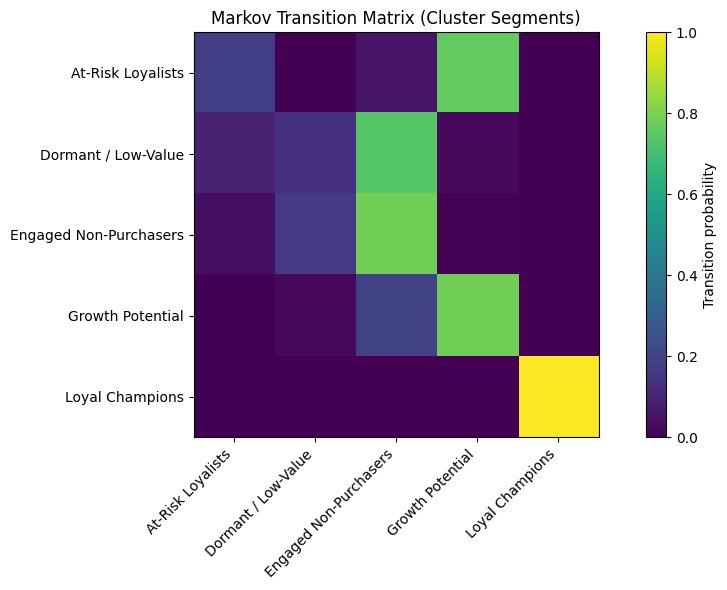

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.imshow(P.values)
plt.xticks(range(P.shape[1]), P.columns, rotation=45, ha="right")
plt.yticks(range(P.shape[0]), P.index)
plt.colorbar(label="Transition probability")
plt.title("Markov Transition Matrix (Cluster Segments)")
plt.tight_layout()
plt.show()